<a href="https://colab.research.google.com/github/maliboo-wow/ml-lab/blob/main/%D0%9B%D0%A04_%D0%91%D1%96%D0%B1%D1%96%D0%BA%D0%BE%D0%B2%D0%B0_%D0%A4%D0%86%D0%A2_3_12.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота №4. Регресійні моделі: глибоке дослідження

**Датасет:** Car Price Prediction Multiple Linear Regression  
https://www.kaggle.com/datasets/hellbuoy/car-price-prediction?select=CarPrice_Assignment.csv

**Мета роботи:** виконати підготовку даних, побудувати та порівняти регресійні моделі для прогнозування ціни автомобіля, оцінити їх якість і проаналізувати отримані результати.

> У шаблоні наведено лише умови завдань. Реалізацію необхідно виконати самостійно у порожніх комірках.


## 1. Завантаження та первинний аналіз даних

Завантажити датасет та виконати його первинний огляд:
- визначити кількість об'єктів і ознак;
- переглянути назви стовпців;
- визначити типи даних;
- визначити цільову змінну;
- вивести основні статистичні характеристики даних.


In [1]:
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)

In [2]:
# завантаження датасету з Kaggle
path = kagglehub.dataset_download("hellbuoy/car-price-prediction")
print("Файли в датасеті:", os.listdir(path))

df = pd.read_csv(os.path.join(path, "CarPrice_Assignment.csv"))
df.head()

100%|██████████| 18.1k/18.1k [00:00<00:00, 23.2MB/s]

Extracting files...
Файли в датасеті: ['Data Dictionary - carprices.xlsx', 'CarPrice_Assignment.csv']


,car_ID,symboling,CarName,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,carlength,carwidth,carheight,curbweight,enginetype,cylindernumber,enginesize,fuelsystem,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
0,1,3,alfa-romero giulia,gas,std,two,convertible,rwd,front,88.6,168.8,64.1,48.8,2548,dohc,four,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495.0
1,2,3,alfa-romero stelvio,gas,std,two,convertible,rwd,front,88.6,168.8,64.1,48.8,2548,dohc,four,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500.0
2,3,1,alfa-romero Quadrifoglio,gas,std,two,hatchback,rwd,front,94.5,171.2,65.5,52.4,2823,ohcv,six,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500.0
3,4,2,audi 100 ls,gas,std,four,sedan,fwd,front,99.8,176.6,66.2,54.3,2337,ohc,four,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950.0
4,5,2,audi 100ls,gas,std,four,sedan,4wd,front,99.4,176.6,66.4,54.3,2824,ohc,five,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450.0


In [3]:
print("Кількість об'єктів (рядків):", df.shape[0])
print("Кількість ознак (стовпців):", df.shape[1])
print()
print("Назви стовпців:")
print(list(df.columns))

Кількість об'єктів (рядків): 205
Кількість ознак (стовпців): 26

Назви стовпців:
['car_ID', 'symboling', 'CarName', 'fueltype', 'aspiration', 'doornumber', 'carbody', 'drivewheel', 'enginelocation', 'wheelbase', 'carlength', 'carwidth', 'carheight', 'curbweight', 'enginetype', 'cylindernumber', 'enginesize', 'fuelsystem', 'boreratio', 'stroke', 'compressionratio', 'horsepower', 'peakrpm', 'citympg', 'highwaympg', 'price']


In [4]:
# типи даних
df.dtypes

,0
car_ID,int64
symboling,int64
CarName,object
fueltype,object
aspiration,object
doornumber,object
carbody,object
drivewheel,object
enginelocation,object
wheelbase,float64


In [5]:
print("Числових стовпців:", df.select_dtypes(include="number").shape[1])
print("Текстових (категоріальних) стовпців:", df.shape[1] - df.select_dtypes(include="number").shape[1])

Числових стовпців: 16
Текстових (категоріальних) стовпців: 10


In [6]:
target = "price"
print("Цільова змінна:", target)

# описова статистика числових ознак
df.describe().T.round(2)

Цільова змінна: price


,count,mean,std,min,25%,50%,75%,max
car_ID,205.0,103.00,59.32,1.00,52.00,103.00,154.00,205.00
symboling,205.0,0.83,1.25,-2.00,0.00,1.00,2.00,3.00
wheelbase,205.0,98.76,6.02,86.60,94.50,97.00,102.40,120.90
carlength,205.0,174.05,12.34,141.10,166.30,173.20,183.10,208.10
carwidth,205.0,65.91,2.15,60.30,64.10,65.50,66.90,72.30
carheight,205.0,53.72,2.44,47.80,52.00,54.10,55.50,59.80
curbweight,205.0,2555.57,520.68,1488.00,2145.00,2414.00,2935.00,4066.00
enginesize,205.0,126.91,41.64,61.00,97.00,120.00,141.00,326.00
boreratio,205.0,3.33,0.27,2.54,3.15,3.31,3.58,3.94
stroke,205.0,3.26,0.31,2.07,3.11,3.29,3.41,4.17


In [7]:
# коротка статистика категоріальних ознак
df.describe(exclude="number").T

,count,unique,top,freq
CarName,205,147,peugeot 504,6
fueltype,205,2,gas,185
aspiration,205,2,std,168
doornumber,205,2,four,115
carbody,205,5,sedan,96
drivewheel,205,3,fwd,120
enginelocation,205,2,front,202
enginetype,205,7,ohc,148
cylindernumber,205,7,four,159
fuelsystem,205,8,mpfi,94


**Висновок:** датасет містить 205 об'єктів і 26 ознак: 16 числових і 10 текстових (категоріальних). Цільова змінна `price` неперервна, ціна від 5 118 до 45 400. Середня ціна (13 277) більша за медіану (10 295), отже є кілька дуже дорогих авто, і розподіл ціни зміщений вправо. `car_ID` це просто номер рядка, а не характеристика автомобіля.

## 2. Перевірка якості даних

Перевірити:
- наявність пропущених значень;
- наявність повних дублікатів;
- кількість унікальних значень в ознаках.

Під час аналізу врахувати, що `car_ID` є унікальним ідентифікатором автомобіля і сам по собі не повинен використовуватися для визначення дублікатів за змістовими характеристиками.


In [8]:
print("Пропущені значення по стовпцях:")
print(df.isnull().sum())
print()
print("Усього пропусків:", df.isnull().sum().sum())

Пропущені значення по стовпцях:
car_ID              0
symboling           0
CarName             0
fueltype            0
aspiration          0
doornumber          0
carbody             0
drivewheel          0
enginelocation      0
wheelbase           0
carlength           0
carwidth            0
carheight           0
curbweight          0
enginetype          0
cylindernumber      0
enginesize          0
fuelsystem          0
boreratio           0
stroke              0
compressionratio    0
horsepower          0
peakrpm             0
citympg             0
highwaympg          0
price               0
dtype: int64

Усього пропусків: 0


In [9]:
# car_ID унікальний для кожного рядка, тому для пошуку дублікатів за змістом його прибираємо
print("Повних дублікатів (разом з car_ID):", df.duplicated().sum())
print("Дублікатів за змістовими ознаками (без car_ID):", df.drop(columns="car_ID").duplicated().sum())

Повних дублікатів (разом з car_ID): 0
Дублікатів за змістовими ознаками (без car_ID): 0


In [10]:
# кількість унікальних значень у кожній ознаці
df.nunique().sort_values(ascending=False)

,0
car_ID,205
price,189
curbweight,171
CarName,147
carlength,75
horsepower,59
wheelbase,53
carheight,49
carwidth,44
enginesize,44


### 2.1. Дослідження стовпця `CarName`

`CarName` має 147 унікальних значень на 205 рядків, тобто майже кожна назва зустрічається один раз. Як ознака у такому вигляді вона не допоможе моделі.

В описі датасету (файл Data Dictionary) ця ознака називається `carCompany`, тобто вона має містити **марку** автомобіля. Перевіримо це.

In [11]:
# опис ознак з файлу Data Dictionary, який іде разом з датасетом
dictionary = pd.read_excel(os.path.join(path, "Data Dictionary - carprices.xlsx"), header=None)
dictionary = dictionary[[7, 11]].dropna()
dictionary.columns = ["Ознака", "Опис"]
pd.set_option("display.max_colwidth", 120)
dictionary

,Ознака,Опис
4,Car_ID,Unique id of each observation (Interger)
5,Symboling,"Its assigned insurance risk rating, A value of +3 indicates that the auto is risky, -3 that it is probably pretty sa..."
6,carCompany,Name of car company (Categorical)
7,fueltype,Car fuel type i.e gas or diesel (Categorical)
8,aspiration,Aspiration used in a car (Categorical)
9,doornumber,Number of doors in a car (Categorical)
10,carbody,body of car (Categorical)
11,drivewheel,type of drive wheel (Categorical)
12,enginelocation,Location of car engine (Categorical)
13,wheelbase,Weelbase of car (Numeric)


In [12]:
# марка: перше слово в назві
df["brand"] = df["CarName"].str.split().str[0]

print("Унікальних марок:", df["brand"].nunique())
df["brand"].value_counts().sort_index()

Унікальних марок: 28


,count
brand,
Nissan,1
alfa-romero,3
audi,7
bmw,8
buick,8
chevrolet,3
dodge,9
honda,13
isuzu,4


Серед марок є підозрілі назви, схожі на інші марки з помилкою:

- `Nissan` і `nissan` (різний регістр);
- `maxda` і `mazda`;
- `porcshce` і `porsche`;
- `toyouta` і `toyota`;
- `vokswagen`, `vw` і `volkswagen`.

Перевіримо, чи це справді ті самі марки. Подивимось на повні назви цих автомобілів і на сусідні рядки, бо в датасеті рядки впорядковані за марками.

In [13]:
suspicious = ["Nissan", "maxda", "porcshce", "toyouta", "vokswagen", "vw"]

df[df["brand"].isin(suspicious)][["car_ID", "CarName", "fueltype", "carbody", "enginesize", "horsepower", "price"]]

,car_ID,CarName,fueltype,carbody,enginesize,horsepower,price
50,51,maxda rx3,gas,hatchback,91,68,5195.0
51,52,maxda glc deluxe,gas,hatchback,91,68,6095.0
89,90,Nissan versa,gas,sedan,97,69,5499.0
126,127,porcshce panamera,gas,hardtop,194,207,32528.0
181,182,toyouta tercel,gas,wagon,161,156,15750.0
182,183,vokswagen rabbit,diesel,sedan,97,52,7775.0
189,190,vw dasher,gas,convertible,109,90,11595.0
190,191,vw rabbit,gas,hatchback,109,90,9980.0


In [14]:
# між якими рядками стоять підозрілі записи
for name in suspicious:
    idx = df.index[df["brand"] == name][0]
    print("Марка:", name)
    print(df.loc[idx - 1 : idx + 1, ["car_ID", "CarName"]].to_string(index=False))
    print()

Марка: Nissan
 car_ID              CarName
     89 mitsubishi mirage g4
     90         Nissan versa
     91          nissan gt-r

Марка: maxda
 car_ID          CarName
     50        jaguar xk
     51        maxda rx3
     52 maxda glc deluxe

Марка: porcshce
 car_ID           CarName
    126     porsche macan
    127 porcshce panamera
    128   porsche cayenne

Марка: toyouta
 car_ID          CarName
    181   toyota starlet
    182   toyouta tercel
    183 vokswagen rabbit

Марка: vokswagen
 car_ID                      CarName
    182               toyouta tercel
    183             vokswagen rabbit
    184 volkswagen 1131 deluxe sedan

Марка: vw
 car_ID           CarName
    189 volkswagen dasher
    190         vw dasher
    191         vw rabbit



In [15]:
# порівняння характеристик: maxda і mazda
df[df["brand"].isin(["maxda", "mazda"])][["car_ID", "CarName", "enginetype", "enginesize", "fuelsystem", "horsepower"]].head(6)

,car_ID,CarName,enginetype,enginesize,fuelsystem,horsepower
50,51,maxda rx3,ohc,91,2bbl,68
51,52,maxda glc deluxe,ohc,91,2bbl,68
52,53,mazda rx2 coupe,ohc,91,2bbl,68
53,54,mazda rx-4,ohc,91,2bbl,68
54,55,mazda glc deluxe,ohc,91,2bbl,68
55,56,mazda 626,rotor,70,4bbl,101


In [16]:
# порівняння характеристик: vokswagen, vw і volkswagen
df[df["brand"].isin(["vokswagen", "vw", "volkswagen"])][["car_ID", "CarName", "enginesize", "fuelsystem", "horsepower"]]

,car_ID,CarName,enginesize,fuelsystem,horsepower
182,183,vokswagen rabbit,97,idi,52
183,184,volkswagen 1131 deluxe sedan,109,mpfi,85
184,185,volkswagen model 111,97,idi,52
185,186,volkswagen type 3,109,mpfi,85
186,187,volkswagen 411 (sw),109,mpfi,85
187,188,volkswagen super beetle,97,idi,68
188,189,volkswagen dasher,109,mpfi,100
189,190,vw dasher,109,mpfi,90
190,191,vw rabbit,109,mpfi,90
191,192,volkswagen rabbit,136,mpfi,110


**Висновок:** перевірка підтвердила, що це ті самі марки, просто з помилками в написанні:

1. Модель у назві відповідає марці: tercel це Toyota, rx3 і glc це Mazda, panamera це Porsche, rabbit і dasher це Volkswagen (`vw` це загальноприйняте скорочення Volkswagen).
2. Ці записи стоять усередині блоку своєї марки, наприклад `porcshce panamera` між `porsche macan` і `porsche cayenne`.
3. Характеристики збігаються з сусідніми авто тієї ж марки: у `maxda` і `mazda` однаковий двигун (91, ohc, 2bbl, 68 к.с.), `vw` і `volkswagen` мають однакові двигуни 109 mpfi.
4. `Nissan` відрізняється від `nissan` тільки великою літерою.

Скоріше за все, помилки з'явились під час ручного введення назв. Тому я виправила їх і об'єднала з правильними марками.

In [17]:
# виправляємо помилки в назвах марок
brand_fix = {
    "maxda": "mazda",
    "porcshce": "porsche",
    "toyouta": "toyota",
    "vokswagen": "volkswagen",
    "vw": "volkswagen",
}
df["brand"] = df["brand"].str.lower().replace(brand_fix)

print("Унікальних марок після виправлення:", df["brand"].nunique())
df["brand"].value_counts()

Унікальних марок після виправлення: 22


,count
brand,
toyota,32
nissan,18
mazda,17
mitsubishi,13
honda,13
subaru,12
volkswagen,12
volvo,11
peugeot,11


In [18]:
# CarName більше не потрібен: марку ми вже винесли в brand
df = df.drop(columns="CarName")
print("Розмір після видалення CarName:", df.shape)

Розмір після видалення CarName: (205, 26)


**Висновок:** пропущених значень немає. Дублікатів теж немає: ні повних, ні за змістовими ознаками без `car_ID`. Більшість категоріальних ознак мають від 2 до 8 значень. `CarName` майже унікальна (147 значень на 205 рядків), тому з неї я виділила марку `brand`. Після виправлення помилок лишилось 22 марки. Сам `CarName` видалено, бо вся корисна інформація з нього вже є в `brand`.

## 3. Робота з car_ID

Зберегти `car_ID` окремо для подальшої ідентифікації автомобілів у результатах прогнозування.  
Не використовувати `car_ID` як ознаку під час навчання моделей.


In [19]:
# зберігаємо car_ID окремо, щоб потім підписувати прогнози
car_ids = df["car_ID"].copy()

print("Кількість car_ID:", len(car_ids))
print("Усі car_ID унікальні:", car_ids.is_unique)
# з ознак для навчання car_ID буде видалено на кроці 5

Кількість car_ID: 205
Усі car_ID унікальні: True


**Висновок:** `car_ID` збережено окремо в `car_ids`, усі 205 значень унікальні. Він не описує автомобіль, тому як ознака для навчання не використовується. Він потрібен тільки щоб підписати прогнози в кінці роботи.

## 4. Дослідження розподілів числових ознак

Дослідити розподіли числових ознак:
- побудувати відповідні графіки;
- обчислити коефіцієнти асиметрії;
- визначити ознаки з найбільш вираженою асиметрією;
- коротко прокоментувати отримані результати.


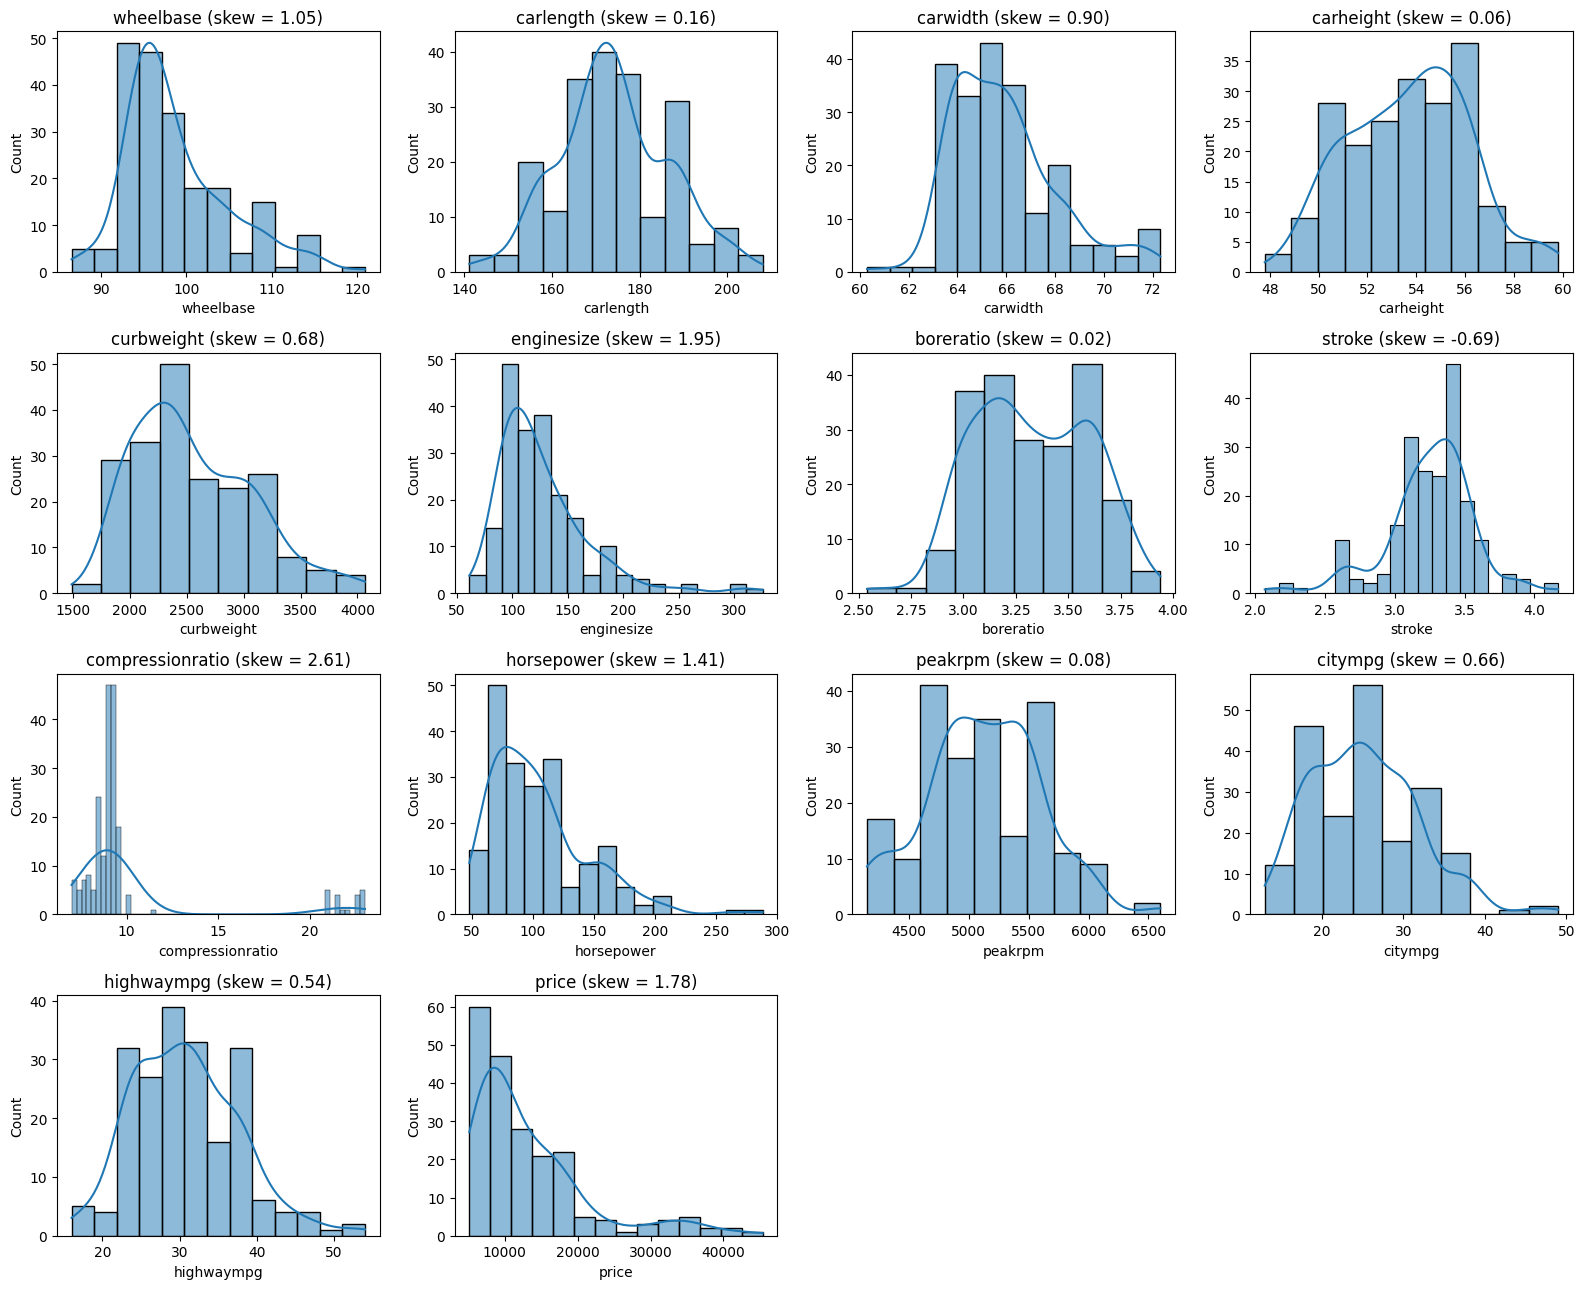

In [20]:
# неперервні числові ознаки (symboling дискретна, car_ID це ідентифікатор)
continuous_cols = ["wheelbase", "carlength", "carwidth", "carheight", "curbweight",
                   "enginesize", "boreratio", "stroke", "compressionratio",
                   "horsepower", "peakrpm", "citympg", "highwaympg"]

fig, axes = plt.subplots(4, 4, figsize=(16, 13))
axes = axes.flatten()

for i, col in enumerate(continuous_cols + ["price"]):
    sns.histplot(df[col], kde=True, ax=axes[i])
    axes[i].set_title(f"{col} (skew = {df[col].skew():.2f})")

for j in range(len(continuous_cols) + 1, 16):
    axes[j].axis("off")

plt.tight_layout()
plt.show()

In [21]:
skew_table = df[continuous_cols + ["price"]].skew().to_frame("Асиметрія")
skew_table["|Асиметрія|"] = skew_table["Асиметрія"].abs()
skew_table["Оцінка"] = np.where(skew_table["|Асиметрія|"] > 1, "сильна",
                       np.where(skew_table["|Асиметрія|"] > 0.5, "помірна", "слабка"))
skew_table = skew_table.sort_values("|Асиметрія|", ascending=False)
skew_table.round(3)

,Асиметрія,|Асиметрія|,Оцінка
compressionratio,2.611,2.611,сильна
enginesize,1.948,1.948,сильна
price,1.778,1.778,сильна
horsepower,1.405,1.405,сильна
wheelbase,1.050,1.050,сильна
carwidth,0.904,0.904,помірна
stroke,-0.690,0.690,помірна
curbweight,0.681,0.681,помірна
citympg,0.664,0.664,помірна
highwaympg,0.540,0.540,помірна


In [22]:
print("Ознаки з найбільшою асиметрією (|skew| > 1):")
print(skew_table[skew_table["|Асиметрія|"] > 1].index.tolist())

Ознаки з найбільшою асиметрією (|skew| > 1):
['compressionratio', 'enginesize', 'price', 'horsepower', 'wheelbase']


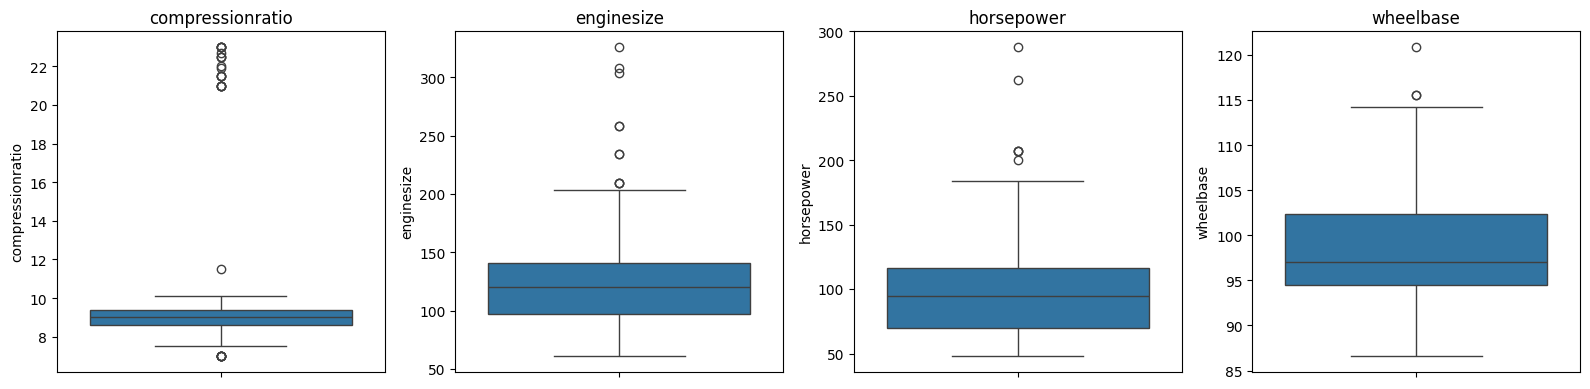

In [23]:
# додатково: boxplot для найбільш асиметричних ознак
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for i, col in enumerate(["compressionratio", "enginesize", "horsepower", "wheelbase"]):
    sns.boxplot(y=df[col], ax=axes[i])
    axes[i].set_title(col)
plt.tight_layout()
plt.show()

**Висновок:** сильна правостороння асиметрія (skew > 1) є у `compressionratio` (2,61), `enginesize` (1,95), `horsepower` (1,41), `wheelbase` (1,05) і в цільовій `price` (1,78). Тобто більшість авто мають невеликі значення, а кілька потужних і дорогих машин утворюють довгий "хвіст" справа. У `compressionratio` видно дві окремі групи: бензинові авто (приблизно 7-10) і дизельні (приблизно 21-23). Майже симетричні `boreratio`, `carheight`, `peakrpm`, `carlength`. Через асиметрію далі використовується перетворення Yeo-Johnson.

## 5. Формування train/test вибірок

Відокремити цільову змінну `price` від ознак та розділити дані на:
- навчальну вибірку — 80%;
- тестову вибірку — 20%.

Забезпечити відтворюваність поділу.  
Окремо зберегти `car_ID` для об'єктів, які потрапили до train і test.

**Важливо:** усі подальші параметри передобробки даних визначати тільки за навчальною вибіркою.


In [24]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=["car_ID", "price"])   # car_ID не є ознакою
y = df["price"]

# разом з X і y ділимо car_ids, щоб знати, які автомобілі потрапили в train і test
X_train, X_test, y_train, y_test, id_train, id_test = train_test_split(
    X, y, car_ids, test_size=0.2, random_state=42
)

X_train = X_train.copy()
X_test = X_test.copy()

print("Train:", X_train.shape, "  Test:", X_test.shape)
print("Частка test:", round(len(X_test) / len(X), 2))
print("car_ID у train:", len(id_train), "  car_ID у test:", len(id_test))
print("Перші car_ID з test:", id_test.head().tolist())

Train: (164, 24)   Test: (41, 24)
Частка test: 0.2
car_ID у train: 164   car_ID у test: 41
Перші car_ID з test: [16, 10, 101, 133, 69]


**Висновок:** дані поділено на 164 об'єкти в train і 41 у test (80/20). `random_state=42` робить поділ відтворюваним. Разом з даними поділено і `car_ids`, тому для кожного об'єкта train і test відомо його `car_ID` (`id_train`, `id_test`). Далі всі межі, кореляції і трансформації рахуються тільки за train.

## 6. Аналіз та обробка викидів

Для неперервних числових ознак навчальної вибірки:
- визначити потенційні викиди методом IQR;
- вивести кількість потенційних викидів для кожної ознаки;
- обґрунтувати спосіб їх обробки.

Для невеликого набору даних не видаляти автоматично всі рядки з викидами. Використати обмеження крайніх значень межами, визначеними за навчальною вибіркою.

Цільову змінну `price` не використовувати для визначення меж викидів.  
До тестової вибірки застосувати ті самі межі, які були отримані за train.


In [25]:
# межі IQR рахуємо тільки за X_train; price не використовуємо
bounds = {}
rows = []

for col in continuous_cols:
    q1 = X_train[col].quantile(0.25)
    q3 = X_train[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    bounds[col] = (lower, upper)

    n_train = ((X_train[col] < lower) | (X_train[col] > upper)).sum()
    n_test = ((X_test[col] < lower) | (X_test[col] > upper)).sum()
    rows.append([col, lower, upper, n_train, n_test])

outliers = pd.DataFrame(rows, columns=["Ознака", "Нижня межа", "Верхня межа",
                                       "Викидів у train", "Викидів у test (за межами train)"])
outliers.sort_values("Викидів у train", ascending=False).round(2)

,Ознака,Нижня межа,Верхня межа,Викидів у train,Викидів у test (за межами train)
8,compressionratio,7.40,10.60,20,8
7,stroke,2.66,3.86,16,4
2,carwidth,60.42,70.42,10,2
9,horsepower,4.75,182.75,7,1
5,enginesize,33.50,205.50,7,3
0,wheelbase,83.10,113.50,6,1
10,peakrpm,3750.00,6550.00,2,0
12,highwaympg,11.50,47.50,1,2
6,boreratio,2.56,4.12,1,0
4,curbweight,998.62,4103.62,0,0


In [26]:
# обмежуємо крайні значення межами з train (рядки не видаляємо)
for col in continuous_cols:
    lower, upper = bounds[col]
    X_train[col] = X_train[col].clip(lower, upper)
    X_test[col] = X_test[col].clip(lower, upper)

# перевірка: після обмеження викидів у train не лишилось
left = 0
for col in continuous_cols:
    lower, upper = bounds[col]
    left += ((X_train[col] < lower) | (X_train[col] > upper)).sum()
print("Викидів у train після обмеження:", left)
print("Рядків у train:", len(X_train), "(нічого не видалено)")

Викидів у train після обмеження: 0
Рядків у train: 164 (нічого не видалено)


**Висновок:** найбільше потенційних викидів у `compressionratio` (20, це дизельні авто), `stroke` (16) і `carwidth` (10). Датасет маленький (164 рядки в train), і якщо видалити всі рядки з викидами, втратиться багато даних. Тому я не видаляла рядки, а обмежила крайні значення межами IQR, порахованими за train (значення за межею замінюється на саму межу). Ті самі межі застосовано до test. `price` у пошуку викидів не використовувалась. Те, що авто дизельне, все одно лишається в ознаці `fueltype`.

## 7. Аналіз кореляцій та відбір ознак

За навчальною вибіркою:
- побудувати матрицю кореляцій числових ознак;
- знайти пари ознак із сильною кореляцією, для яких `|r| > 0.85`;
- для кожної такої пари залишити одну ознаку;
- під час вибору врахувати силу зв'язку кожної ознаки з цільовою змінною `price`;
- вивести список сильно корельованих пар та перелік ознак, які видаляються.

Із тестової вибірки видалити ті самі ознаки.  
Не використовувати тестову вибірку для прийняття рішення про відбір ознак.


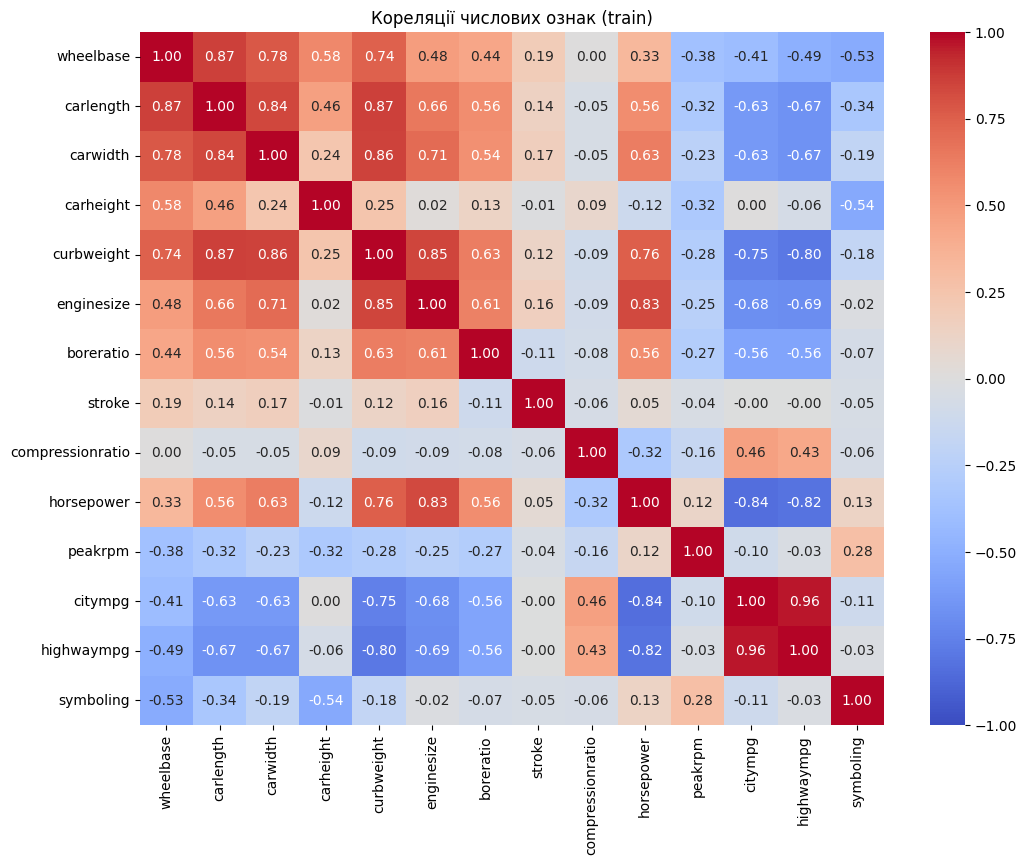

In [27]:
numeric_cols = continuous_cols + ["symboling"]

corr = X_train[numeric_cols].corr()

plt.figure(figsize=(12, 9))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Кореляції числових ознак (train)")
plt.show()

In [28]:
# зв'язок кожної ознаки з ціною (теж тільки train)
target_corr = X_train[numeric_cols].corrwith(y_train)
target_corr.sort_values(ascending=False).to_frame("Кореляція з price").round(3)

,Кореляція з price
enginesize,0.846
curbweight,0.824
horsepower,0.807
carwidth,0.732
carlength,0.652
boreratio,0.547
wheelbase,0.504
carheight,0.044
symboling,-0.005
stroke,-0.006


In [29]:
# пари ознак із |r| > 0.85
pairs = []
for i in range(len(numeric_cols)):
    for j in range(i + 1, len(numeric_cols)):
        a = numeric_cols[i]
        b = numeric_cols[j]
        r = corr.loc[a, b]
        if abs(r) > 0.85:
            pairs.append([a, b, r, target_corr[a], target_corr[b]])

pairs_df = pd.DataFrame(pairs, columns=["Ознака 1", "Ознака 2", "r", "r(1, price)", "r(2, price)"])
pairs_df = pairs_df.reindex(pairs_df["r"].abs().sort_values(ascending=False).index).reset_index(drop=True)
pairs_df.round(3)

,Ознака 1,Ознака 2,r,"r(1, price)","r(2, price)"
0,citympg,highwaympg,0.964,-0.711,-0.716
1,wheelbase,carlength,0.867,0.504,0.652
2,carlength,curbweight,0.866,0.652,0.824
3,carwidth,curbweight,0.858,0.732,0.824


In [30]:
# з кожної пари видаляємо ознаку, яка слабше пов'язана з price
to_drop = []
for _, row in pairs_df.iterrows():
    a, b = row["Ознака 1"], row["Ознака 2"]
    if a in to_drop or b in to_drop:
        continue   # пара вже "розв'язана"
    if abs(row["r(1, price)"]) < abs(row["r(2, price)"]):
        to_drop.append(a)
    else:
        to_drop.append(b)

print("Ознаки, які видаляються:", to_drop)

Ознаки, які видаляються: ['citympg', 'wheelbase', 'carlength', 'carwidth']


In [31]:
X_train = X_train.drop(columns=to_drop)
X_test = X_test.drop(columns=to_drop)    # ті самі ознаки з test

continuous_cols = [c for c in continuous_cols if c not in to_drop]
numeric_cols = continuous_cols + ["symboling"]

# перевірка: чи лишились сильно корельовані пари
corr_new = X_train[numeric_cols].corr().abs()
max_r = corr_new.where(~np.eye(len(corr_new), dtype=bool)).max().max()   # без діагоналі
print("Максимальна |r| між ознаками, що лишились:", round(max_r, 3))
print("Ознаки, що лишились:", continuous_cols)

Максимальна |r| між ознаками, що лишились: 0.849
Ознаки, що лишились: ['carheight', 'curbweight', 'enginesize', 'boreratio', 'stroke', 'compressionratio', 'horsepower', 'peakrpm', 'highwaympg']


**Висновок:** знайдено 4 пари з |r| > 0.85: `citympg`-`highwaympg` (0,96), `wheelbase`-`carlength` (0,87), `carlength`-`curbweight` (0,87), `carwidth`-`curbweight` (0,86). З кожної пари видалено ознаку, яка слабше пов'язана з ціною: `citympg`, `wheelbase`, `carlength`, `carwidth`. Залишилась `curbweight`, у неї сильний зв'язок з ціною (0,82). Після видалення максимальна кореляція між ознаками 0,849, тобто сильно корельованих пар більше немає. Рішення прийнято тільки за train, з test просто видалено ті самі стовпці.

## 8. Підготовка числових і категоріальних ознак

Розділити ознаки на:
- неперервні числові;
- дискретну числову ознаку `symboling`;
- категоріальні.

Для неперервних числових ознак виконати послідовно:
1. перетворення Yeo–Johnson для зменшення асиметрії;
2. масштабування за допомогою StandardScaler.

Для `symboling` виконати масштабування без Yeo–Johnson.

Категоріальні ознаки закодувати методом One-Hot Encoding. Передбачити коректну обробку категорій у test, яких не було у train.

Усі перетворення об'єднати в єдиний механізм передобробки даних, який навчається тільки на `X_train`.


In [32]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PowerTransformer, StandardScaler, OneHotEncoder

num_features = continuous_cols                     # неперервні
discrete_features = ["symboling"]                  # дискретна
cat_features = [c for c in X_train.columns if c not in num_features + discrete_features]  # категоріальні

print("Неперервні:", num_features)
print("Дискретна:", discrete_features)
print("Категоріальні:", cat_features)

Неперервні: ['carheight', 'curbweight', 'enginesize', 'boreratio', 'stroke', 'compressionratio', 'horsepower', 'peakrpm', 'highwaympg']
Дискретна: ['symboling']
Категоріальні: ['fueltype', 'aspiration', 'doornumber', 'carbody', 'drivewheel', 'enginelocation', 'enginetype', 'cylindernumber', 'fuelsystem', 'brand']


In [33]:
def make_num_pipeline():
    # 1) Yeo-Johnson, 2) StandardScaler
    return Pipeline([
        ("yeo_johnson", PowerTransformer(method="yeo-johnson", standardize=False)),
        ("scaler", StandardScaler()),
    ])

def make_preprocessor():
    return ColumnTransformer([
        ("num", make_num_pipeline(), num_features),
        ("sym", StandardScaler(), discrete_features),
        # handle_unknown="ignore": нова категорія в test стане рядком з нулів, помилки не буде
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_features),
    ])

preprocessor = make_preprocessor()
preprocessor.fit(X_train)            # навчаємо тільки на train

print("Ознак після передобробки:", preprocessor.transform(X_train).shape[1])
print("Train після передобробки:", preprocessor.transform(X_train).shape)
print("Test після передобробки:", preprocessor.transform(X_test).shape)

Ознак після передобробки: 69
Train після передобробки: (164, 69)
Test після передобробки: (41, 69)


In [34]:
# перевірка: чи є в test категорії, яких немає в train
for col in cat_features:
    new_cats = set(X_test[col]) - set(X_train[col])
    if new_cats:
        print(col, "- нові категорії в test:", new_cats)
print("Перевірку завершено")

cylindernumber - нові категорії в test: {'three'}
Перевірку завершено


**Висновок:** ознаки поділено на 9 неперервних, 1 дискретну (`symboling`) і 10 категоріальних (разом з `brand`). Неперервні проходять Yeo-Johnson і StandardScaler, `symboling` тільки StandardScaler, категоріальні кодуються One-Hot. Після цього вийшло 69 ознак. У test є категорія `cylindernumber = three`, якої немає в train. Завдяки `handle_unknown="ignore"` помилки немає: для такої категорії всі стовпці One-Hot будуть нулями. Усі кроки зібрані в один `ColumnTransformer`, який навчається тільки на `X_train`.

## 9. Перевірка трансформації числових ознак

Перевірити результат трансформації неперервних числових ознак:
- застосувати до train ту саму послідовність перетворень, яка буде використана в моделях;
- повторно обчислити коефіцієнти асиметрії;
- порівняти їх із початковими значеннями;
- зробити короткий висновок щодо ефективності трансформації.


In [35]:
# та сама послідовність, що і в моделях: Yeo-Johnson -> StandardScaler
num_check = make_num_pipeline()
X_train_num_t = pd.DataFrame(num_check.fit_transform(X_train[num_features]),
                             columns=num_features, index=X_train.index)

skew_compare = pd.DataFrame({
    "Початкова (весь датасет)": df[num_features].skew(),
    "Train до трансформації": X_train[num_features].skew(),
    "Train після трансформації": X_train_num_t.skew(),
})
skew_compare["Зменшилась?"] = skew_compare["Train після трансформації"].abs() < skew_compare["Train до трансформації"].abs()
skew_compare.round(3)

,Початкова (весь датасет),Train до трансформації,Train після трансформації,Зменшилась?
carheight,0.063,0.028,-0.005,True
curbweight,0.681,0.712,0.050,True
enginesize,1.948,0.962,0.045,True
boreratio,0.020,0.063,-0.006,True
stroke,-0.690,-0.398,0.016,True
compressionratio,2.611,0.056,0.005,True
horsepower,1.405,0.851,0.066,True
peakrpm,0.075,0.040,-0.004,True
highwaympg,0.540,0.244,-0.012,True


In [36]:
print("Середня |асиметрія| до:", round(skew_compare["Train до трансформації"].abs().mean(), 3))
print("Середня |асиметрія| після:", round(skew_compare["Train після трансформації"].abs().mean(), 3))

Середня |асиметрія| до: 0.373
Середня |асиметрія| після: 0.023


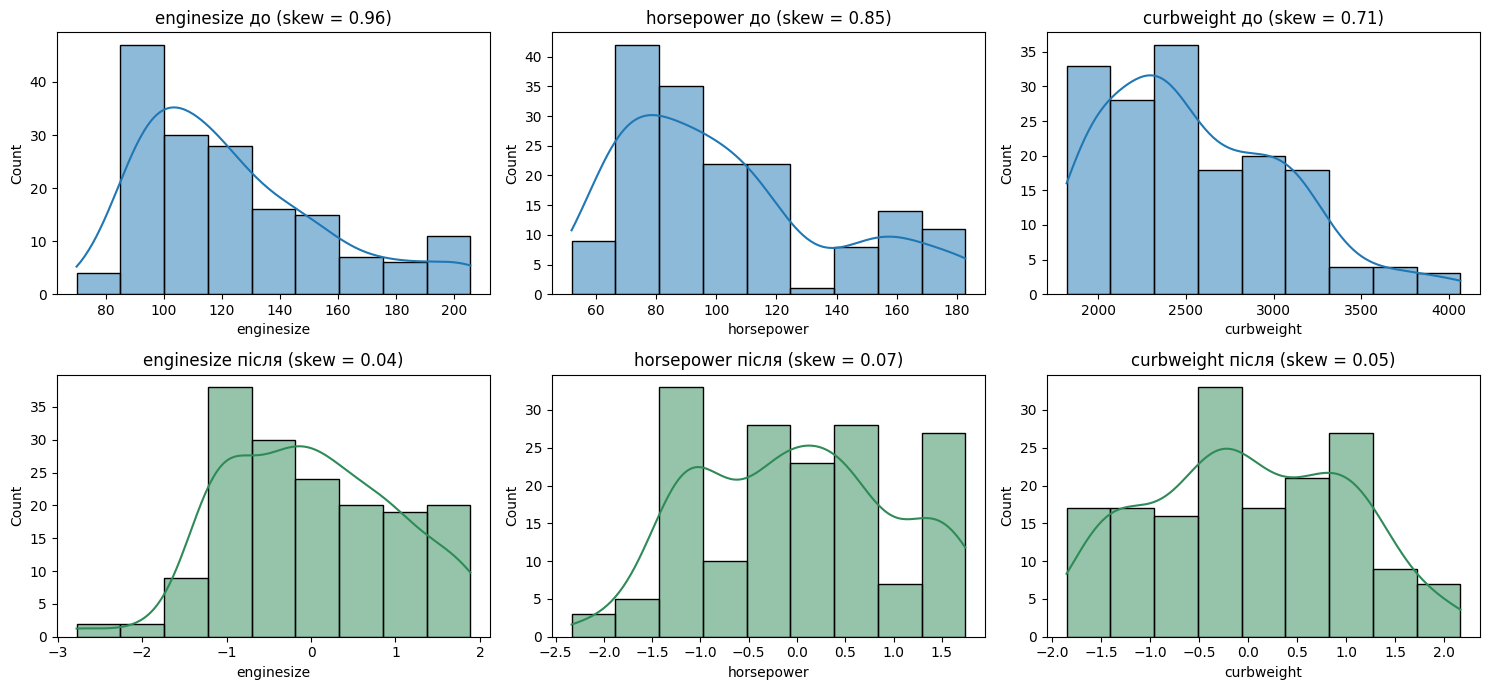

In [37]:
# додатково: розподіл до і після для кількох ознак
cols_to_show = ["enginesize", "horsepower", "curbweight"]
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for i, col in enumerate(cols_to_show):
    sns.histplot(X_train[col], kde=True, ax=axes[0, i])
    axes[0, i].set_title(f"{col} до (skew = {X_train[col].skew():.2f})")
    sns.histplot(X_train_num_t[col], kde=True, ax=axes[1, i], color="seagreen")
    axes[1, i].set_title(f"{col} після (skew = {X_train_num_t[col].skew():.2f})")
plt.tight_layout()
plt.show()

**Висновок:** після трансформації асиметрія зменшилась у всіх ознаках, середня |skew| впала з 0,373 до 0,023. Наприклад, у `enginesize` вона зменшилась з 0,96 до 0,05, у `horsepower` з 0,85 до 0,07. У `compressionratio` асиметрію майже повністю прибрало вже обмеження викидів (2,61 у всьому датасеті, 0,06 у train після обмеження). Отже, трансформація ефективна: розподіли стали майже симетричними.

## 10. Побудова регресійних моделей

Побудувати та навчити такі моделі:
- Linear Regression;
- Ridge Regression;
- Lasso Regression;
- Random Forest Regressor;
- Gradient Boosting Regressor;
- Support Vector Regressor (SVR).

Для кожної моделі створити єдиний Pipeline, який містить:
1. попередню обробку ознак;
2. відповідну регресійну модель.

Використати однакову схему підготовки даних для коректного порівняння моделей.


In [38]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR

# для кожної моделі свій Pipeline: однакова передобробка + модель
models = {
    "Linear Regression": Pipeline([("preprocessing", make_preprocessor()), ("model", LinearRegression())]),
    "Ridge": Pipeline([("preprocessing", make_preprocessor()), ("model", Ridge(alpha=1.0))]),
    "Lasso": Pipeline([("preprocessing", make_preprocessor()), ("model", Lasso(alpha=1.0, max_iter=50000))]),
    "Random Forest": Pipeline([("preprocessing", make_preprocessor()), ("model", RandomForestRegressor(random_state=42))]),
    "Gradient Boosting": Pipeline([("preprocessing", make_preprocessor()), ("model", GradientBoostingRegressor(random_state=42))]),
    # ціни великі (тисячі), тому для SVR беремо великий C (див. перевірку нижче)
    "SVR": Pipeline([("preprocessing", make_preprocessor()), ("model", SVR(kernel="rbf", C=50000))]),
}

for name in models:
    print(name)

Linear Regression
Ridge
Lasso
Random Forest
Gradient Boosting
SVR


In [39]:
# додатково: чому для SVR змінено C
from sklearn.metrics import r2_score

svr_default = Pipeline([("preprocessing", make_preprocessor()), ("model", SVR())])
svr_default.fit(X_train, y_train)
print("SVR з C=1 (за замовчуванням), R2 на test:", round(r2_score(y_test, svr_default.predict(X_test)), 4))
# з C=1 модель майже не навчається, бо значення price дуже великі порівняно з C

SVR з C=1 (за замовчуванням), R2 на test: -0.0997


**Висновок:** створено 6 моделей, кожна у своєму Pipeline з однаковою передобробкою, тому порівняння чесне. SVR чутливий до масштабу цільової змінної: з параметром за замовчуванням `C=1` він дає R² ≈ -0,10, тобто гірше, ніж просто прогнозувати середнє. Тому для SVR взято `C=50000`.

## 11. Оцінювання якості моделей

Для кожної моделі:
- виконати навчання на тренувальній вибірці;
- отримати прогноз для тестової вибірки;
- обчислити метрики **R², MAE, MSE та MAPE**.

`MAPE` подати у відсотках.

Результати всіх моделей об'єднати в одну порівняльну таблицю та впорядкувати за значенням R² від найбільшого до найменшого.

Під час інтерпретації врахувати:
- R² — чим більше, тим краще;
- MAE, MSE, MAPE — чим менше, тим краще.


In [40]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error, mean_absolute_percentage_error

results = []
predictions = {}

for name, model in models.items():
    model.fit(X_train, y_train)            # навчання тільки на train
    y_pred = model.predict(X_test)         # прогноз для test
    predictions[name] = y_pred

    results.append({
        "Модель": name,
        "R2": r2_score(y_test, y_pred),
        "MAE": mean_absolute_error(y_test, y_pred),
        "MSE": mean_squared_error(y_test, y_pred),
        "MAPE, %": mean_absolute_percentage_error(y_test, y_pred) * 100,
        "R2 (train)": r2_score(y_train, model.predict(X_train)),   # для перевірки перенавчання
    })

results_df = pd.DataFrame(results).sort_values("R2", ascending=False).reset_index(drop=True)
results_df.round(4)

,Модель,R2,MAE,MSE,"MAPE, %",R2 (train)
0,Random Forest,0.9542,1351.1871,3.613633e+06,9.8566,0.9842
1,SVR,0.9322,1673.8903,5.349131e+06,14.6609,0.9920
2,Gradient Boosting,0.9304,1727.4037,5.492942e+06,12.0502,0.9932
3,Linear Regression,0.8794,2156.0903,9.518255e+06,16.3764,0.9597
4,Lasso,0.8782,2105.2143,9.612671e+06,15.1336,0.9595
5,Ridge,0.8537,2368.4155,1.155081e+07,18.2026,0.9482


In [41]:
# додатково: різниця R2 між train і test (ознака перенавчання)
results_df["Різниця R2 (train - test)"] = results_df["R2 (train)"] - results_df["R2"]
results_df[["Модель", "R2 (train)", "R2", "Різниця R2 (train - test)"]].round(4)

,Модель,R2 (train),R2,Різниця R2 (train - test)
0,Random Forest,0.9842,0.9542,0.0300
1,SVR,0.9920,0.9322,0.0598
2,Gradient Boosting,0.9932,0.9304,0.0628
3,Linear Regression,0.9597,0.8794,0.0803
4,Lasso,0.9595,0.8782,0.0813
5,Ridge,0.9482,0.8537,0.0945


**Висновок:** найкраща модель Random Forest: R² = 0,954, MAE ≈ 1 351, MAPE ≈ 9,9%. Далі йдуть SVR (R² = 0,932, MAPE 14,7%) і Gradient Boosting (R² = 0,930, MAPE 12,1%). Лінійні моделі слабші: R² від 0,854 до 0,879, MAPE 15-18%. Найгірша Ridge. Порядок за MAE і MSE майже такий самий, як за R². У всіх моделей R² на train вищий, ніж на test. Найменша різниця у Random Forest (0,03), найбільша у лінійних моделей (0,08-0,09). Gradient Boosting і SVR на train мають R² ≈ 0,99, а на test 0,93, тобто є невелике перенавчання.

## 12. Пояснення вибору типу моделі

Пояснити, чому класифікаційна модель, наприклад Logistic Regression, не підходить для безпосереднього прогнозування неперервної ціни автомобіля.

Зазначити, до якого типу задачі належить прогнозування `price` та чому моделі, використані в роботі, відповідають цій задачі.


**Відповідь:**

Прогнозування `price` це **задача регресії**, бо ціна це неперервне число (наприклад, 13 499 або 16 500), а не клас.

Logistic Regression, попри назву, це модель **класифікації**. Вона рахує ймовірність того, що об'єкт належить до певного класу (від 0 до 1), і видає мітку класу. Щоб її використати, довелося б розбити ціни на групи, наприклад "дешеві" і "дорогі". Тоді ми б не отримали конкретну ціну, а метрики R², MAE, MSE і MAPE втратили б сенс.

Усі моделі в роботі (Linear, Ridge, Lasso, Random Forest Regressor, Gradient Boosting Regressor, SVR) це **регресійні** моделі. Вони прогнозують число і навчаються зменшувати різницю між прогнозом і фактичною ціною, тому підходять для цієї задачі.

## 13. Візуальне порівняння прогнозів

Для кожної побудованої моделі зобразити співвідношення:
- фактичних значень `price`;
- прогнозованих значень `price`.

Додати лінію ідеального прогнозу та проаналізувати, наскільки близько до неї розташовані прогнозовані значення. Звернути увагу на великі відхилення.


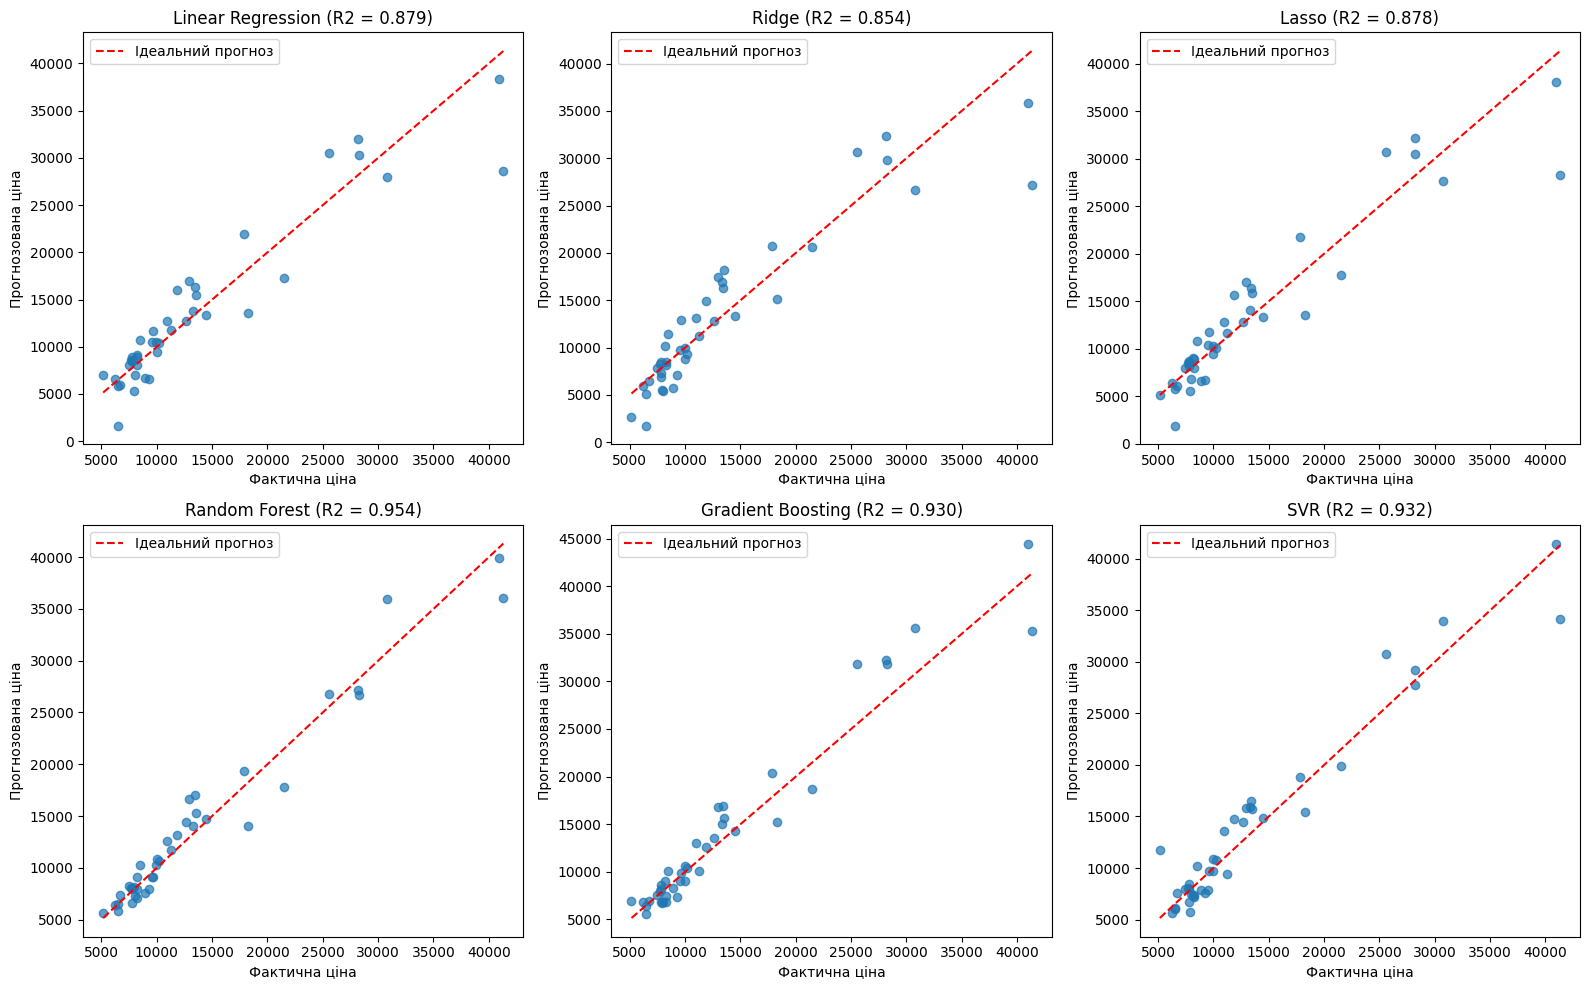

In [42]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

min_p, max_p = y_test.min(), y_test.max()

for i, (name, y_pred) in enumerate(predictions.items()):
    axes[i].scatter(y_test, y_pred, alpha=0.7)
    axes[i].plot([min_p, max_p], [min_p, max_p], "r--", label="Ідеальний прогноз")
    axes[i].set_title(f"{name} (R2 = {r2_score(y_test, y_pred):.3f})")
    axes[i].set_xlabel("Фактична ціна")
    axes[i].set_ylabel("Прогнозована ціна")
    axes[i].legend()

plt.tight_layout()
plt.show()

In [43]:
# найбільші відхилення: 5 автомобілів з найбільшою помилкою для кожної моделі
for name, y_pred in predictions.items():
    errors = pd.DataFrame({
        "car_ID": id_test.values,
        "Фактична": y_test.values,
        "Прогноз": y_pred,
    })
    errors["Абс. помилка"] = (errors["Фактична"] - errors["Прогноз"]).abs()
    print(name)
    print(errors.sort_values("Абс. помилка", ascending=False).head(5).round(0).to_string(index=False))
    print()

Linear Regression
 car_ID  Фактична  Прогноз  Абс. помилка
     17   41315.0  28634.0       12681.0
     68   25552.0  30520.0        4968.0
     31    6479.0   1664.0        4815.0
     66   18280.0  13539.0        4741.0
    203   21485.0  17245.0        4240.0

Ridge
 car_ID  Фактична  Прогноз  Абс. помилка
     17   41315.0  27199.0       14116.0
     74   40960.0  35823.0        5137.0
     68   25552.0  30630.0        5078.0
     31    6479.0   1771.0        4708.0
    102   13499.0  18189.0        4690.0

Lasso
 car_ID  Фактична  Прогноз  Абс. помилка
     17   41315.0  28267.0       13048.0
     68   25552.0  30742.0        5190.0
     66   18280.0  13535.0        4745.0
     31    6479.0   1937.0        4542.0
    195   12940.0  16995.0        4055.0

Random Forest
 car_ID  Фактична  Прогноз  Абс. помилка
     17   41315.0  36049.0        5266.0
     16   30760.0  35977.0        5217.0
     66   18280.0  14049.0        4231.0
    203   21485.0  17767.0        3718.0
    195   

**Висновок:** у Random Forest, Gradient Boosting і SVR точки лежать близько до лінії ідеального прогнозу. У лінійних моделей розкид більший, особливо для дорогих авто. Найбільша помилка майже у всіх моделей для `car_ID` 17 (BMW, 41 315): лінійна регресія прогнозує приблизно 28 634 (помилка 12 681), Random Forest приблизно 36 049 (помилка 5 266). Дорогих авто в train мало, тому їх прогнозувати найважче. Також лінійна регресія для дешевого авто `car_ID` 31 (6 479) дала занадто низький прогноз, лише 1 664.

## 14. Прогноз для 10 автомобілів

Випадково вибрати 10 автомобілів із тестової вибірки.

За допомогою моделі Random Forest отримати для них прогноз ціни та сформувати таблицю з такими даними:
- `car_ID`;
- фактична ціна;
- прогнозована ціна;
- абсолютна помилка;
- абсолютна відсоткова помилка.

Прокоментувати отримані результати.


In [44]:
rf_model = models["Random Forest"]   # вже навчена модель

sample = X_test.sample(10, random_state=42)
sample_pred = rf_model.predict(sample)

rf_table = pd.DataFrame({
    "car_ID": id_test.loc[sample.index].values,
    "Марка": sample["brand"].values,
    "Фактична ціна": y_test.loc[sample.index].values,
    "Прогнозована ціна": sample_pred,
})
rf_table["Абсолютна помилка"] = (rf_table["Фактична ціна"] - rf_table["Прогнозована ціна"]).abs()
rf_table["Абсолютна відсоткова помилка, %"] = rf_table["Абсолютна помилка"] / rf_table["Фактична ціна"] * 100

rf_table.round(2)

,car_ID,Марка,Фактична ціна,Прогнозована ціна,Абсолютна помилка,"Абсолютна відсоткова помилка, %"
0,26,dodge,6692.0,7355.28,663.27,9.91
1,176,toyota,9988.0,10883.90,895.90,8.97
2,148,subaru,10198.0,10661.08,463.08,4.54
3,17,bmw,41315.0,36048.88,5266.12,12.75
4,69,buick,28248.0,26697.37,1550.63,5.49
5,147,subaru,7463.0,8272.67,809.67,10.85
6,144,subaru,9960.0,10238.06,278.06,2.79
7,85,mitsubishi,14489.0,14738.95,249.95,1.73
8,195,volvo,12940.0,16647.24,3707.24,28.65
9,160,toyota,7788.0,7915.58,127.58,1.64


In [45]:
print("Середня абсолютна помилка для 10 авто:", round(rf_table["Абсолютна помилка"].mean(), 2))
print("Середня відсоткова помилка для 10 авто:", round(rf_table["Абсолютна відсоткова помилка, %"].mean(), 2), "%")
print("Найбільша відсоткова помилка:", round(rf_table["Абсолютна відсоткова помилка, %"].max(), 2), "%")

Середня абсолютна помилка для 10 авто: 1401.15
Середня відсоткова помилка для 10 авто: 8.73 %
Найбільша відсоткова помилка: 28.65 %


**Висновок:** для 10 випадкових авто з test середня відсоткова помилка Random Forest 8,73%, середня абсолютна помилка приблизно 1 401. Для 7 авто з 10 помилка менша за 10%, найточніші прогнози для Toyota (`car_ID` 160, 1,6%) і Mitsubishi (`car_ID` 85, 1,7%). Найбільша відсоткова помилка у Volvo (`car_ID` 195): факт 12 940, прогноз 16 647 (28,65%). Найбільша абсолютна помилка у дорогого BMW (`car_ID` 17, 5 266). Загалом для більшості авто прогноз близький до реальної ціни.

## 15. Висновки

Сформулювати підсумкові висновки за результатами роботи.

У висновках:
- порівняти якість усіх моделей;
- проаналізувати R², MAE, MSE і MAPE;
- зазначити, яка модель показала найкращі результати за отриманими метриками;
- прокоментувати величину похибок;
- звернути увагу на можливі ознаки перенавчання;
- коротко оцінити вплив попередньої обробки даних на результати моделювання.


**Загальний висновок:**

1 Я побудувала 6 моделей регресії: Linear Regression, Ridge, Lasso, Random Forest, Gradient Boosting і SVR. Для всіх моделей була однакова передобробка даних.

2 Найкраща модель Random Forest: R2 = 0.954, MAE = 1351, MAPE = 9.9%. Далі йдуть SVR (R2 = 0.932) і Gradient Boosting (R2 = 0.930). Лінійні моделі найслабші, у них R2 від 0.854 до 0.879.

3 Середня помилка Random Forest приблизно 1351, це близько 10% від середньої ціни. Найбільше модель помиляється на дорогих авто, бо таких машин у даних мало.

4 У всіх моделей R2 на train трохи вищий, ніж на test, тобто є невелике перенавчання. Найменша різниця у Random Forest (0.03), найбільша у лінійних моделей (0.08-0.09). Скоріше за все, це через малу кількість даних.

5 Передобробка допомогла: я виправила назви марок, обмежила викиди без видалення рядків, прибрала 4 сильно корельовані ознаки, а Yeo-Johnson зменшив асиметрію майже до нуля. Усі параметри передобробки я рахувала тільки за train.

## Загальні вимоги до виконання

- Не використовувати тестову вибірку для визначення меж викидів, кореляційного відбору ознак, навчання трансформерів, масштабування або кодування категорій.
- Усі параметри передобробки мають визначатися тільки за навчальною вибіркою.
- Фінальні метрики моделей обчислювати на тестовій вибірці.
- Не використовувати `car_ID` як предиктор.
- Не видаляти спостереження або ознаки без пояснення причини.
- До кожного основного етапу додати короткий змістовний висновок.
- У підсумкових висновках спиратися на отримані метрики та графіки.
